# Injection and recovery

Add point sources of known flux to a real 50 arcsec field and measure
them with the MER-prior path of the pipeline. Injection and recovery both
use the nearest GRID-PSF sample, so the test checks the fitting code, not
the PSF model itself.

We look at the recovered flux scale, the pull `(recovered - true) /
reported error`, and the fraction recovered with a valid fit and S/N > 5.
The injected signal is noiseless: source Poisson noise is not simulated.

In [1]:
import numpy as np
from astropy.table import vstack
import matplotlib.pyplot as plt

import euclid_phot as ep

from euclid_phot.config import DEFAULT_DATA_DIR
from euclid_phot.injection import run_injection_recovery, summarize_recovery

TARGET_RA, TARGET_DEC = 269.48, 67.30
CUTOUT_SIZE_ARCSEC = 50.0
DATA_DIR = DEFAULT_DATA_DIR  # download cache; set EUCLID_PHOT_DATA_DIR to move it

## 1. Bright sources: the flux scale

Thirty VIS point sources at 10 to 100 microJansky.

In [2]:
cat_b, truth_b, result_b = run_injection_recovery(
    data_dir=DATA_DIR, target_ra=TARGET_RA, target_dec=TARGET_DEC,
    cutout_size_arcsec=CUTOUT_SIZE_ARCSEC,
    bands=("VIS",), n_inject=30, flux_range_ujy=(10.0, 100.0), rng=1,
    injection_psf_product="grid", psf_product="grid", return_result=True)
s_b = summarize_recovery(cat_b, truth_b, band="VIS")
print(f"recovered {s_b['n_recovered']}/{s_b['n_injected']} injections")
print(f"flux bias:        median(out/true) = {s_b['ratio_median']:.4f}")
print(f"recovery scatter: mad_std(out/true) = {s_b['ratio_mad']:.4f}")


recovered 30/30 injections
flux bias:        median(out/true) = 1.0001
recovery scatter: mad_std(out/true) = 0.0002


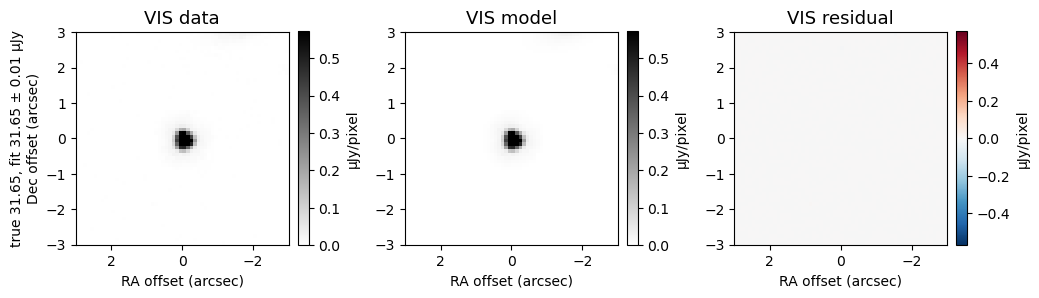

In [3]:
# One of the injected sources: the image with it added, the model, and the residual.
flux_true = np.asarray(truth_b["flux_vis_sersic"])
k = int(np.argmin(np.abs(flux_true - np.median(flux_true))))  # a typical one
r = list(cat_b["object_id"]).index(truth_b["object_id"][k])
label = f"true {flux_true[k]:.2f}, fit {cat_b['flux_VIS_ujy'][r]:.2f} ± {cat_b['flux_err_VIS_ujy'][r]:.2f} µJy"
ep.viz.show_source_cutouts(result_b, [(truth_b["ra"][k], truth_b["dec"][k])],
                           band="VIS", size_arcsec=6.0, labels=[label])
plt.show()

*An injected point source of typical flux in VIS: the image with it added, the fitted model,
and the residual, with the true and the recovered flux in the row label.*

## 2. Faint sources: fluxes, uncertainties, and completeness

Twenty-five seeds of 40 sources each, at S/N of about 5 to 20 in VIS, Y, J,
and H. Each seed starts from the original image, and the 1000 injections are
combined. A pull width (scaled MAD) near unity means the reported errors match the
recovered scatter.

In [4]:
FAINT = {"VIS": (0.04, 0.12), "Y": (0.4, 1.2),
         "J": (0.4, 1.2), "H": (0.45, 1.3)}
catalogs, truths = [], []
for seed in range(25):
    cat, truth = run_injection_recovery(
        data_dir=DATA_DIR, target_ra=TARGET_RA, target_dec=TARGET_DEC,
        cutout_size_arcsec=CUTOUT_SIZE_ARCSEC, bands=tuple(FAINT),
        n_inject=40, flux_range_ujy=FAINT, rng=seed,
        injection_psf_product="grid", psf_product="grid")
    # Injected rows have negative object_id; offset them so the seeds do not collide.
    cat = cat[np.isin(cat['object_id'], truth['object_id'])].copy()
    cat['object_id'] -= seed * 40
    truth['object_id'] -= seed * 40
    catalogs.append(cat)
    truths.append(truth)

cat_f = vstack(catalogs, metadata_conflicts='silent')
truth_f = vstack(truths, metadata_conflicts='silent')
summaries = {band: summarize_recovery(cat_f, truth_f, band=band, n_bins=10) for band in FAINT}
print(f"{'band':>5} {'fitted/total':>13} {'ratio':>7} {'pull':>7} {'S/N>5 fraction':>15}")
for band, s in summaries.items():
    print(f"{band:>5} {s['n_recovered']:>6}/{s['n_injected']:<6} "
          f"{s['ratio_median']:7.3f} {s['pull_std']:7.3f} {s['completeness']:15.3f}")

 band  fitted/total   ratio    pull  S/N>5 fraction
  VIS   1000/1000     1.004   0.809           0.983
    Y   1000/1000     1.012   0.932           0.994
    J   1000/1000     0.999   0.917           0.996
    H   1000/1000     1.010   1.002           0.992


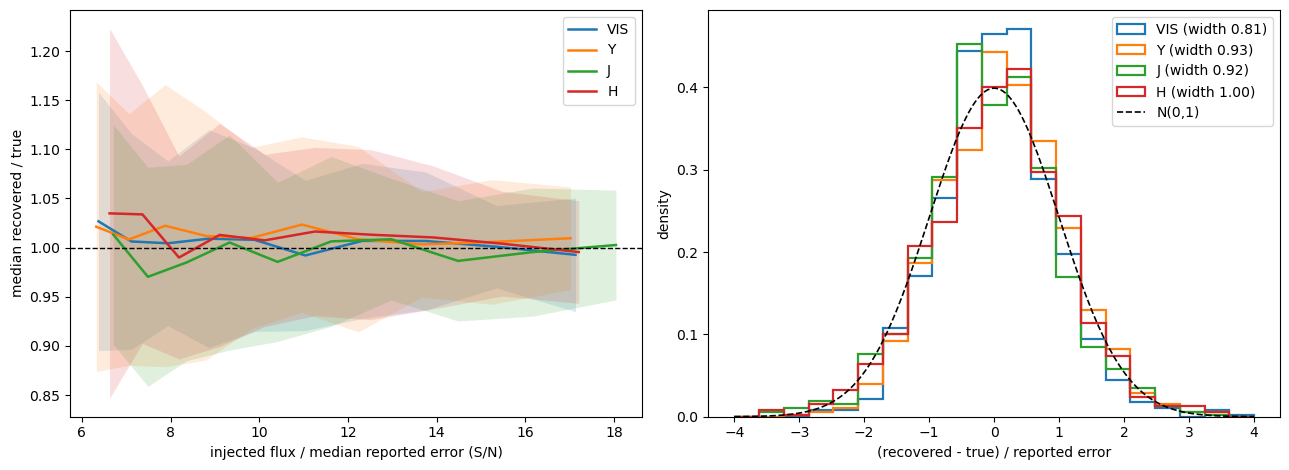

In [5]:
fig, (ax_bias, ax_pull) = plt.subplots(1, 2, figsize=(13, 4.8))

injected = cat_f['object_id'] < 0
for band in FAINT:
    b = summaries[band]['bins']
    # Bands were injected at the same S/N, not the same flux: put them on one axis.
    snr_per_ujy = 1.0 / np.nanmedian(cat_f[f'flux_err_{band}_ujy'][injected])
    centre = np.sqrt(b['flux_lo_ujy'] * b['flux_hi_ujy']) * snr_per_ujy
    line, = ax_bias.plot(centre, b['ratio_median'], '-', lw=1.8, label=band)
    ax_bias.fill_between(centre, b['ratio_median'] - b['ratio_mad'], b['ratio_median'] + b['ratio_mad'],
                         color=line.get_color(), alpha=0.15, lw=0)
ax_bias.axhline(1.0, color='k', ls='--', lw=1)
ax_bias.set_xlabel('injected flux / median reported error (S/N)')
ax_bias.set_ylabel('median recovered / true')
ax_bias.legend()

x = np.linspace(-4, 4, 200)
for band in FAINT:
    ax_pull.hist(summaries[band]['pull'], bins=np.linspace(-4, 4, 22),
                 density=True, histtype='step', lw=1.6,
                 label=f"{band} (width {summaries[band]['pull_std']:.2f})")
ax_pull.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), 'k--', lw=1.2, label='N(0,1)')
ax_pull.set_xlabel('(recovered - true) / reported error')
ax_pull.set_ylabel('density')
ax_pull.legend()
plt.tight_layout()
plt.show()

*Left: the median recovered over true flux per bin of injected S/N, with the one-sigma scatter
of the individual recoveries shaded. Every band is injected at S/N of about 5 to 20, which is
0.04 to 0.12 microJansky in VIS and 0.4 to 1.3 in Y, J, and H. Right: the pull distributions
against a unit Gaussian.*